# 06 · Final Run

**Goal:** score the frozen system once on the two sets nobody has looked at, with the same code, gates, and baselines as notebook 05.

| Set | What it checks |
|---|---|
| TEST (597 entries) | the same kind of entries as TRAIN and VAL, never used for any choice |
| Holdout file (800 entries) | conditions never seen: later dates, new phrasings, a lateral hire with no billing history |

**This notebook runs once.** The models, cutoffs, and gates were fixed before it ran (notebook 04 and `src/evaluate.py`), and nothing is tuned after seeing these results. A result that falls short is reported as it is. Changes made after the first final run are listed under Limitations.

**Questions**
1. Do TEST and the holdout file confirm what VAL showed?
2. Does the classifier still beat the rules on entries it has never seen?
3. Does it pass the gates on both sets?
4. Where does it do worse on the holdout file, and why?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

sys.path.insert(0, "../src")
from rules import run_rules, cmid_only, score
from pipeline import load_reference, load_entries, mark_true_matters, score_entries, decide
from evaluate import (parse_metrics, pair_metrics, action_metrics, headline, slice_table, add_failure_types, check_decisions,
                      stress_variants, changed_decisions, check_gates, dataset_hash, matter_history, GATES, TRACKED)

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
HOLDOUT_PATH = Path("../data/synthetic_time_entries_v3_HOLDOUT.xlsx")
RESULTS_DIR = Path("../results")
SETTING = "default"     # the chosen cutoffs from notebook 04
SEED = 210
SETS = ["TEST", "HOLDOUT"]   # which sets to score ["TEST", "HOLDOUT"]; ["TEST"] scores TEST and leaves the holdout file unopened
SKIP_CLIENTS = ["Firm"]   # an ordinary word, so "firm meeting" doesn't name a client (as in notebook 00)

## 2. Load the frozen system and the two sets

- **Frozen system:** notebook 04's models and cutoffs, notebook 03's rule settings, and the gates in `src/evaluate.py`.
- **TEST:** read from the main file with `load_entries`, keeping only TEST entries. Its fingerprint has to match the one notebook 05 saved, so it's the same untouched set.
- **Holdout:** the separate file, read the same way. Its Matter Master has to match the main file's, since the models only know those 103 matters. It's only opened when `SETS` includes it.

In [3]:
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
rules_config = json.loads((RESULTS_DIR / "03_config.json").read_text())
val_report = json.loads((RESULTS_DIR / "05_eval_report.json").read_text())
CLIENT_COL, MATTER_COL, PHRASE_MIN = feature_config["client_col"], feature_config["matter_col"], feature_config["phrase_min"]

encoder = SentenceTransformer(feature_config["embedding_model"])
ref = load_reference(DATA_PATH, RESULTS_DIR, encoder, SETTING)
valid_cmids = set(ref["matters"]["cmid"])

main_entries, main_answers = load_entries(DATA_PATH, ref, SKIP_CLIENTS)
test_answers = main_answers[main_answers["split"] == "TEST"].reset_index(drop=True)
test_entries = main_entries[main_entries["entry_id"].isin(test_answers["entry_id"])].reset_index(drop=True)
sets = {"TEST": (test_entries, test_answers)}
if "HOLDOUT" in SETS:
    holdout_matters = pd.read_excel(HOLDOUT_PATH, sheet_name="Matter Master", dtype=str)
    assert set(holdout_matters["CMID"]) == valid_cmids
    sets["HOLDOUT"] = load_entries(HOLDOUT_PATH, ref, SKIP_CLIENTS)

assert dataset_hash(test_answers, ["entry_id"]) == val_report["fingerprints"]["TEST ids"]
assert val_report["setting"] == SETTING
print("Cutoffs:", ref["cutoffs"])
pd.DataFrame({name: entries["source_format"].value_counts() for name, (entries, _) in sets.items()}).fillna(0).astype(int)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Cutoffs: {'auto_min': 0.9, 'no_match_min': 0.9, 'multi_min': 0.15, 'correct_typed_cmid': True}


,TEST,HOLDOUT
source_format,,
TYPED,317,452
HANDWRITTEN,124,164
PDF,107,113
EMAIL,49,71


## 3. Run every method on both sets

No labels are used until scoring:
- **Classifier:** `decide` (`src/pipeline.py`) builds the clues, runs both models, applies the cutoffs, and writes the reasons. It's the same call the deployed service makes.
- **Rules and CMID only:** the notebook 03 baselines, on the same clues.

In [4]:
runs = {}
for name, (entries, answers) in sets.items():
    pairs, top, decisions = decide(entries, ref)
    pairs = mark_true_matters(pairs, answers)
    runs[name] = {"entries": entries, "answers": answers, "pairs": pairs, "top": top,
                  "classifier": score(decisions, answers).merge(entries[["entry_id", "source_format"]], on="entry_id"),
                  "rules": score(run_rules(pairs, rules_config["rules"]), answers),
                  "CMID only": score(run_rules(pairs, rules_config["rules"], cmid_only), answers)}
    print(f"{name}: {len(entries)} entries | {len(pairs):,} pairs")

TEST: 597 entries | 61,491 pairs
HOLDOUT: 800 entries | 82,400 pairs


## 4. Headline results

The same numbers as notebook 05, for each method and set. VAL is shown for comparison, but VAL was used to choose between versions, so TEST and the holdout file are the unbiased numbers.

In [5]:
cols = ["decided_precision", "ci_low", "ci_high", "straight_through", "review_share", "silent_errors", "matter_accuracy",
        "multi_caught", "no_match_precision", "shortlist_hit"]
table = {(name, method): headline(run[method]) for name, run in runs.items() for method in ["CMID only", "rules", "classifier"]}
table[("VAL", "classifier")] = val_report["results"]
table = pd.DataFrame(table).T[cols].rename_axis(["set", "method"])
table.round(3)

decided_precision  ci_low  ci_high  straight_through  \
set     method                                                             
TEST    CMID only               0.705   0.645    0.764             0.466   
        rules                   0.846   0.808    0.880             0.608   
        classifier              0.969   0.950    0.987             0.705   
HOLDOUT CMID only               0.732   0.690    0.773             0.480   
        rules                   0.881   0.846    0.912             0.611   
        classifier              0.981   0.962    0.995             0.658   
VAL     classifier              0.977   0.964    0.989             0.735   

                    review_share  silent_errors  matter_accuracy  \
set     method                                                     
TEST    CMID only          0.534           82.0            0.400   
        rules              0.302           48.0            0.670   
        classifier         0.157           13.0            0.863   
HOLDOUT CMID only          0.520          103.0            0.410   
        rules              0.294           50.0            0.670   
        classifier         0.196           10.0            0.859   
VAL     classifier         0.151            9.0            0.870   

                    multi_caught  no_match_precision  shortlist_hit  
set     method                                                       
TEST    CMID only          0.000                 NaN          0.661  
        rules              0.108               0.704          0.556  
        classifier         0.730               1.000          0.787  
HOLDOUT CMID only          0.000                 NaN          0.721  
        rules              0.184               0.758          0.634  
        classifier         0.921               1.000          0.796  
VAL     classifier         0.811               0.947          0.791

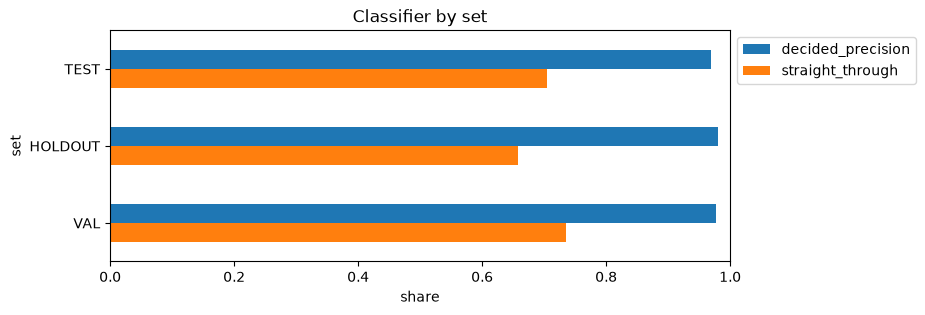

In [6]:
ax = table.xs("classifier", level="method")[["decided_precision", "straight_through"]].plot.barh(figsize=(8, 3), xlim=(0, 1), title="Classifier by set")
ax.set_xlabel("share")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.invert_yaxis()
plt.show()

- **TEST and the holdout file confirm VAL:** 96.9% and 98.1% of automatic decisions are right, vs. 97.7% on VAL. The 97% target holds on entries the system never saw.
- **The classifier beats the rules on both sets:** 13 silent errors vs. 48 on TEST and 10 vs. 50 on the holdout file, with about half as much review on TEST (16% vs. 30%).
- **The holdout file decides a little less with no person** (66% vs. 71% on TEST), mostly from the lateral hire with no history (section 6).

## 5. Stage by stage

Extraction (emails), the pair model, and the action model on their own, so a drop can be traced to the step it comes from. The metrics are the same as notebook 05's metrics at a glance.

In [7]:
stages = {}
for name, run in runs.items():
    emails = run["entries"][run["entries"]["source_format"] == "EMAIL"]
    stages[name] = {**{f"email_{k}": v for k, v in parse_metrics(emails, run["answers"], ref["client_names"]).items()},
                    **pair_metrics(run["pairs"]),
                    **{f"step 2 AUROC, {label}": auroc for label, auroc in action_metrics(run["top"], run["answers"])["auroc"].items()}}
pd.DataFrame(stages).round(3)

,TEST,HOLDOUT
email_emails,49.000,71.000
email_hours_found,1.000,1.000
email_client_filled,0.796,0.789
email_right_client,0.773,0.738
email_wrong_client,0.023,0.015
entries,597.000,800.000
top_1,0.913,0.896
top_3,0.971,0.957
mrr,0.945,0.929
auroc,0.994,0.991


- **Emails:** hours are found every time, and the client field is filled for about 8 in 10, rarely with a wrong client.
- **Step 1 holds up:** the right matter is first for about 9 in 10 entries, MRR is 0.93 to 0.95, and AUROC is 0.99 on both sets.
- **Step 2 earns its place:** P(auto) has an AUROC of 0.93 on both sets, vs. 0.82 to 0.83 for step 1's top probability alone.
- **Calibration slips on the holdout file** (0.064 vs. 0.044 on TEST), which has new phrasings the models never saw.

## 6. Slices

The classifier's numbers by source format, entry type, whether the right matter has past entries, and whether the timekeeper has billing history. Small groups (under 10 entries) are left out of the first two.

In [8]:
slice_cols = ["entries", "decided_precision", "straight_through", "review_share", "silent_errors", "matter_accuracy"]
by_format = pd.concat({name: slice_table(run["classifier"], "source_format") for name, run in runs.items()})
by_format[slice_cols].round(3)

entries  decided_precision  straight_through  \
TEST    EMAIL           49.0              0.944             0.735   
        HANDWRITTEN    124.0              0.955             0.718   
        PDF            107.0              0.974             0.729   
        TYPED          317.0              0.977             0.688   
HOLDOUT EMAIL           71.0              0.946             0.521   
        HANDWRITTEN    164.0              0.973             0.689   
        PDF            113.0              0.971             0.619   
        TYPED          452.0              0.990             0.677   

                     review_share  silent_errors  matter_accuracy  
TEST    EMAIL               0.122            2.0            0.776  
        HANDWRITTEN         0.145            4.0            0.911  
        PDF                 0.150            2.0            0.860  
        TYPED               0.170            5.0            0.858  
HOLDOUT EMAIL               0.310            2.0            0.704  
        HANDWRITTEN         0.201            3.0            0.884  
        PDF                 0.239            2.0            0.858  
        TYPED               0.166            3.0            0.874

In [9]:
by_type = pd.concat({name: slice_table(run["classifier"], "key_entry_category") for name, run in runs.items()})
by_type[slice_cols].round(3)

entries  decided_precision  straight_through  \
TEST    AMBIGUOUS              36.0              0.923             0.361   
        CLEAN                 154.0              1.000             0.851   
        CLOSED_OR_NOT_OPEN     15.0              1.000             0.400   
        INCOMPLETE            137.0              0.991             0.847   
        MESSY                 132.0              0.991             0.803   
        MULTI_NAMED            24.0              0.000             0.292   
        MULTI_UNNAMED          13.0              0.000             0.154   
        NO_MATCH               36.0              1.000             0.667   
        WRONG_CMID_SILENT      29.0              0.833             0.207   
        WRONG_CMID_TEXT        21.0              1.000             0.476   
HOLDOUT AMBIGUOUS              48.0              0.920             0.521   
        CLEAN                 229.0              0.995             0.834   
        CLOSED_OR_NOT_OPEN     16.0              1.000             0.312   
        INCOMPLETE            192.0              0.993             0.734   
        MESSY                 168.0              0.991             0.690   
        MULTI_NAMED            19.0              0.000             0.053   
        MULTI_UNNAMED          19.0                NaN             0.000   
        NO_MATCH               37.0              0.957             0.622   
        WRONG_CMID_SILENT      40.0              0.833             0.300   
        WRONG_CMID_TEXT        32.0              0.917             0.375   

                            review_share  silent_errors  matter_accuracy  
TEST    AMBIGUOUS                  0.639            1.0            0.667  
        CLEAN                      0.110            0.0            0.968  
        CLOSED_OR_NOT_OPEN         0.000            0.0            0.933  
        INCOMPLETE                 0.080            1.0            0.942  
        MESSY                      0.189            1.0            0.962  
        MULTI_NAMED                0.042            7.0            0.167  
        MULTI_UNNAMED              0.000            2.0            0.846  
        NO_MATCH                   0.306            0.0            0.667  
        WRONG_CMID_SILENT          0.172            1.0            0.552  
        WRONG_CMID_TEXT            0.048            0.0            0.810  
HOLDOUT AMBIGUOUS                  0.458            2.0            0.667  
        CLEAN                      0.114            1.0            0.956  
        CLOSED_OR_NOT_OPEN         0.000            0.0            0.688  
        INCOMPLETE                 0.182            1.0            0.911  
        MESSY                      0.262            1.0            0.940  
        MULTI_NAMED                0.105            1.0            0.474  
        MULTI_UNNAMED              0.000            0.0            0.684  
        NO_MATCH                   0.378            1.0            0.595  
        WRONG_CMID_SILENT          0.175            2.0            0.650  
        WRONG_CMID_TEXT            0.219            1.0            0.688

In [10]:
for run in runs.values():
    run["classifier"]["matter_history"] = matter_history(run["classifier"], ref["past_cmids"])
by_history = pd.concat({name: slice_table(run["classifier"], "matter_history", min_entries=1) for name, run in runs.items()})
by_history[slice_cols].round(3)

entries  decided_precision  straight_through  \
TEST    new client or matter     36.0              1.000             0.667   
        new matter                5.0              0.500             0.400   
        seen before             556.0              0.970             0.710   
HOLDOUT new client or matter     37.0              0.957             0.622   
        new matter               28.0              1.000             0.321   
        seen before             735.0              0.982             0.672   

                              review_share  silent_errors  matter_accuracy  
TEST    new client or matter         0.306            0.0            0.667  
        new matter                   0.200            1.0            0.400  
        seen before                  0.147           12.0            0.879  
HOLDOUT new client or matter         0.378            1.0            0.595  
        new matter                   0.500            0.0            0.679  
        seen before                  0.176            9.0            0.879

In [11]:
for run in runs.values():
    has_history = run["classifier"]["tk_id"].isin(ref["history"]["tk_id"])
    run["classifier"]["timekeeper"] = has_history.map({True: "has billing history", False: "no billing history"})
by_timekeeper = pd.concat({name: slice_table(run["classifier"], "timekeeper", min_entries=1) for name, run in runs.items()})
by_timekeeper[slice_cols].round(3)

entries  decided_precision  straight_through  \
TEST    has billing history    597.0              0.969             0.705   
HOLDOUT has billing history    706.0              0.982             0.694   
        no billing history      94.0              0.972             0.383   

                             review_share  silent_errors  matter_accuracy  
TEST    has billing history         0.157           13.0            0.863  
HOLDOUT has billing history         0.159            9.0            0.881  
        no billing history          0.479            1.0            0.691

- **By format:** typed, PDF, and handwritten entries stay between 95.5% and 99%. Emails trail at about 94.5% on both sets and go to review more often on the holdout file.
- **By entry type:** clean, incomplete, and messy entries are right 99% to 100% of the time when decided automatically. Named multi-matter entries are where silent errors pile up on TEST (7).
- **New matters:** on the holdout file, the 28 entries on matters with no past entries have no silent errors, and half go to review.
- **The lateral hire goes to review, not to the wrong matter.** With no billing history, 38% of their 94 entries are decided with no person (vs. 69% for everyone else) and 48% go to review, with 1 silent error.

## 7. Failure types and checks

The same failure types as notebook 05, ordered by cost, and the same checks on every decision.

In [12]:
for run in runs.values():
    run["classifier"] = add_failure_types(run["classifier"])
pd.DataFrame({name: run["classifier"]["failure_type"].value_counts() for name, run in runs.items()}).fillna(0).astype(int)

,TEST,HOLDOUT
failure_type,,
false multi-matter alarm,17,34
missed second matter,1,2
"review, right matter not in shortlist",9,17
"review, top pick right",62,100
silent error,13,10
wrong flag suggestion,13,17


In [13]:
cols = ["entry_id", "source_format", "key_entry_category", "action", "pred_cmid", "key_true_cmid", "reason_short"]
pd.concat({name: run["classifier"].loc[run["classifier"]["failure_type"] == "silent error", cols] for name, run in runs.items()})

entry_id source_format key_entry_category      action pred_cmid  \
TEST    88   T-00646         TYPED        MULTI_NAMED  AUTO_MATCH  7633.002   
        117  T-00844         TYPED        MULTI_NAMED  AUTO_MATCH  2960.001   
        149  T-01094         TYPED        MULTI_NAMED  AUTO_MATCH  8340.001   
        196  T-01366         EMAIL        MULTI_NAMED  AUTO_MATCH  8340.001   
        206  T-01412   HANDWRITTEN      MULTI_UNNAMED  AUTO_MATCH  7222.002   
        326  T-02239   HANDWRITTEN      MULTI_UNNAMED  AUTO_MATCH  9028.003   
        351  T-02402         EMAIL          AMBIGUOUS  AUTO_MATCH  2960.001   
        414  T-02764   HANDWRITTEN        MULTI_NAMED  AUTO_MATCH  2201.001   
        430  T-02836         TYPED         INCOMPLETE  AUTO_MATCH  8340.001   
        474  T-03133         TYPED              MESSY  AUTO_MATCH  6230.001   
        510  T-03424           PDF        MULTI_NAMED  AUTO_MATCH  5524.002   
        538  T-03586   HANDWRITTEN  WRONG_CMID_SILENT  AUTO_MATCH  5524.002   
        586  T-03926           PDF        MULTI_NAMED  AUTO_MATCH  2960.001   
HOLDOUT 16   H-00017         EMAIL          AMBIGUOUS  AUTO_MATCH  7215.005   
        116  H-00117   HANDWRITTEN              CLEAN  AUTO_MATCH  7215.005   
        117  H-00118         TYPED        MULTI_NAMED  AUTO_MATCH  7215.005   
        256  H-00257           PDF  WRONG_CMID_SILENT  AUTO_MATCH  3012.005   
        299  H-00300         EMAIL          AMBIGUOUS  AUTO_MATCH  8340.001   
        355  H-00356   HANDWRITTEN           NO_MATCH  AUTO_MATCH  7222.002   
        491  H-00492         TYPED  WRONG_CMID_SILENT  AUTO_MATCH  7222.002   
        503  H-00504   HANDWRITTEN    WRONG_CMID_TEXT  AUTO_MATCH  7633.002   
        519  H-00520           PDF              MESSY  AUTO_MATCH  2960.001   
        634  H-00635         TYPED         INCOMPLETE  AUTO_MATCH  7215.005   

            key_true_cmid                reason_short  
TEST    88       7633.002          Typed CMID matches  
        117      2960.001          Typed CMID matches  
        149      8340.001   You've billed this matter  
        196      8340.001   You've billed this matter  
        206      7222.002   You've billed this matter  
        326      9028.003   You've billed this matter  
        351      2960.003        Typed client matches  
        414      2201.001          Typed CMID matches  
        430      8340.003   You've billed this matter  
        474      6230.002        Typed client matches  
        510      5524.002   You've billed this matter  
        538      4471.004        Typed CMID corrected  
        586      2960.001          Typed CMID matches  
HOLDOUT 16       7215.003        Typed client matches  
        116      7215.004        Typed CMID corrected  
        117      7215.003  Narrative names the matter  
        256      2960.001          Typed CMID matches  
        299      8340.002   You've billed this matter  
        355          NONE   You've billed this matter  
        491      2960.001          Typed CMID matches  
        503      6103.003          Typed CMID matches  
        519      2960.002        Typed client matches  
        634      7215.003        Typed client matches

In [14]:
checks = {name: check_decisions(run["classifier"], run["pairs"], valid_cmids, CLIENT_COL, MATTER_COL, PHRASE_MIN) for name, run in runs.items()}
pd.DataFrame({name: c["violations"] for name, c in checks.items()})

,TEST,HOLDOUT
check,,
suggested matters exist in Matter Master,0,0
auto-matched matter was open on the work date,0,0
auto-match against a valid typed CMID says it corrected it,0,0
NO_MATCH suggests no matter,0,0
every decision has a reason,0,0
auto-match reason is true for that entry,0,0
stated confidence matches the probability,0,0
review shortlist has 3 different matters,0,0


- **Most failures are extra review** on entries whose top pick was already right (62 on TEST, 100 on the holdout file).
- **9 of TEST's 13 silent errors are multi-matter entries** billed to their main matter, so the second matter's time is missed.
- **Most other silent errors are sibling matters:** 3 of TEST's other 4, and 6 of the holdout file's 10, are the right client but a different matter.
- **No decision breaks a rule** on either set.

## 8. Stress tests

The same changes as notebook 05 (`stress_variants`), applied to each set and run through the whole pipeline again.

In [15]:
stress = {}
for name, run in runs.items():
    rows, changed = {}, {}
    for variant, changed_entries in stress_variants(run["entries"], seed=SEED).items():
        _, _, out = score_entries(changed_entries, ref)
        rows[variant] = headline(score(out, run["answers"]))
        changed[variant] = changed_decisions(run["classifier"], out)
    stress[name] = pd.DataFrame(rows).T.assign(changed=pd.Series(changed))
stress = pd.concat(stress)
stress[["decided_precision", "ci_low", "straight_through", "review_share", "silent_errors", "matter_accuracy", "changed"]].round(3)

decided_precision  ci_low  \
TEST    same, upper case narrative               0.969   0.950   
        same, extra spaces                       0.969   0.950   
        OCR noise (10% of letters)               0.968   0.952   
        typo in client name                      0.964   0.942   
        typo in narrative                        0.978   0.958   
        CMID digits swapped                      0.952   0.925   
        CMID left blank                          0.953   0.927   
        client left blank                        0.945   0.904   
        new timekeeper (no history)              0.958   0.935   
HOLDOUT same, upper case narrative               0.981   0.962   
        same, extra spaces                       0.981   0.962   
        OCR noise (10% of letters)               0.982   0.958   
        typo in client name                      0.981   0.963   
        typo in narrative                        0.982   0.965   
        CMID digits swapped                      0.949   0.919   
        CMID left blank                          0.959   0.936   
        client left blank                        0.978   0.968   
        new timekeeper (no history)              0.967   0.947   

                                     straight_through  review_share  \
TEST    same, upper case narrative              0.705         0.157   
        same, extra spaces                      0.705         0.157   
        OCR noise (10% of letters)              0.672         0.193   
        typo in client name                     0.704         0.162   
        typo in narrative                       0.677         0.186   
        CMID digits swapped                     0.625         0.305   
        CMID left blank                         0.643         0.251   
        client left blank                       0.484         0.313   
        new timekeeper (no history)             0.638         0.238   
HOLDOUT same, upper case narrative              0.658         0.196   
        same, extra spaces                      0.658         0.196   
        OCR noise (10% of letters)              0.618         0.231   
        typo in client name                     0.656         0.198   
        typo in narrative                       0.628         0.226   
        CMID digits swapped                     0.591         0.329   
        CMID left blank                         0.581         0.292   
        client left blank                       0.459         0.309   
        new timekeeper (no history)             0.601         0.262   

                                     silent_errors  matter_accuracy  changed  
TEST    same, upper case narrative            13.0            0.863    0.000  
        same, extra spaces                    13.0            0.863    0.000  
        OCR noise (10% of letters)            11.0            0.844    0.121  
        typo in client name                   14.0            0.859    0.032  
        typo in narrative                      9.0            0.858    0.101  
        CMID digits swapped                   16.0            0.821    0.214  
        CMID left blank                       18.0            0.796    0.233  
        client left blank                     16.0            0.737    0.330  
        new timekeeper (no history)           15.0            0.814    0.273  
HOLDOUT same, upper case narrative            10.0            0.859    0.000  
        same, extra spaces                    10.0            0.859    0.000  
        OCR noise (10% of letters)             9.0            0.850    0.130  
        typo in client name                    9.0            0.858    0.032  
        typo in narrative                      8.0            0.848    0.105  
        CMID digits swapped                   14.0            0.818    0.208  
        CMID left blank                       19.0            0.771    0.245  
        client left blank                      8.0            0.719    0.344  
        ne

- **Formatting changes nothing** on either set.
- **Messier input keeps precision between 94.5% and 98%,** mostly by sending more to review.
- **The hardest changes:** a blank client on TEST (94.5%) and swapped CMID digits on the holdout file (94.9%).

## 9. Gates

The same blockers and tracked lines as notebook 05, with the rules baseline from the same set.

In [16]:
results, gate_tables = {}, {}
for name, run in runs.items():
    rules_results = headline(run["rules"])
    set_stress = stress.loc[name]
    step2 = action_metrics(run["top"], run["answers"])
    results[name] = headline(run["classifier"]) | pair_metrics(run["pairs"]) | {
        **{f"{label}_auroc": step2.loc[label, "auroc"] for label in ["auto", "multi", "no_match"]},
        "rules_decided_precision": rules_results["decided_precision"],
        "rules_silent_errors": rules_results["silent_errors"],
        "violations": int(checks[name]["violations"].sum()),
        "formatting_changed": max(set_stress.loc["same, upper case narrative", "changed"], set_stress.loc["same, extra spaces", "changed"]),
        "stress_worst_precision": float(set_stress["decided_precision"].min()),
        "format_worst_precision": float(by_format.loc[name, "decided_precision"].min()),
    }
    gate_tables[name] = pd.concat({"blocker": check_gates(results[name], GATES), "tracked": check_gates(results[name], TRACKED)})
    blockers = gate_tables[name].loc["blocker", "passed"]
    print(f"{name}: {blockers.sum()} of {len(blockers)} blockers passed | tracked: {gate_tables[name].loc['tracked', 'passed'].sum()} of {len(TRACKED)}")

gates = pd.concat(gate_tables)
gates[["value", "rule", "passed", "source"]]

TEST: 7 of 10 blockers passed | tracked: 1 of 2
HOLDOUT: 8 of 10 blockers passed | tracked: 1 of 2


value  \
                gate                                             
TEST    blocker decided precision, low end of range      0.950   
                silent errors per auto-match             0.033   
                decided precision above the rules        0.950   
                fewer silent errors than the rules      13.000   
                decisions breaking a check               0.000   
                decisions changed by formatting          0.000   
                new-client calls right                   1.000   
                multi-matter entries caught              0.730   
                right matter in review shortlist         0.787   
                top-pick calibration error               0.044   
        tracked worst stress test, decided precision     0.945   
                worst source format, decided precision   0.944   
HOLDOUT blocker decided precision, low end of range      0.962   
                silent errors per auto-match             0.020   
                decided precision above the rules        0.962   
                fewer silent errors than the rules      10.000   
                decisions breaking a check               0.000   
                decisions changed by formatting          0.000   
                new-client calls right                   1.000   
                multi-matter entries caught              0.921   
                right matter in review shortlist         0.796   
                top-pick calibration error               0.064   
        tracked worst stress test, decided precision     0.949   
                worst source format, decided precision   0.946   

                                                                                     rule  \
                gate                                                                        
TEST    blocker decided precision, low end of range                               >= 0.95   
                silent errors per auto-match                                      <= 0.03   
                decided precision above the rules       > rules_decided_precision (0.846)   
                fewer silent errors than the rules         < rules_silent_errors (48.000)   
                decisions breaking a check                                           <= 0   
                decisions changed by formatting                                      <= 0   
                new-client calls right                                             >= 0.9   
                multi-matter entries caught                                        >= 0.7   
                right matter in review shortlist                                   >= 0.8   
                top-pick calibration error                                        <= 0.05   
        tracked worst stress test, decided precision                              >= 0.95   
                worst source format, decided precision                             >= 0.9   
HOLDOUT blocker decided precision, low end of range                               >= 0.95   
                silent errors per auto-match                                      <= 0.03   
                decided precision above the rules       > rules_decided_precision (0.881)   
                fewer silent errors than the rules         < rules_silent_errors (50.000)   
                decisions breaking a check                                           <= 0   
                decisions changed by formatting                                      <= 0   
                new-client calls right                                             >= 0.9   
                multi-matter entries caught                                        >= 0.7   
                right matter in review shortlist                                   >= 0.8   
                top-pick calibration error                                        <= 0.05   
        tracked worst stress test, decided precision                              >= 0.95   
               

- **TEST passes 7 of 10 blockers and the holdout file 8 of 10.** Every miss is close: TEST's precision low end lands just under 95%, silent errors per auto-match are 3.3% vs. a 3% line, and the review shortlist is 78.7% and 79.6% vs. 80%. Holdout calibration is 0.064 vs. 0.05.
- **The worst stress test misses its tracked line on both sets** (94.5% and 94.9% vs. 95%).
- **The baseline gates pass easily:** precision is well above the rules', with about a quarter of their silent errors.

## 10. Save

- `06_final_report.json`: every number above for each set, the gate results, the setting, and the set fingerprints
- `06_decisions.csv`: one row per TEST and holdout entry for each method, with the reasons and the answer key

In [17]:
report = {"setting": SETTING, "cutoffs": ref["cutoffs"],
          "fingerprints": {f"{name} ids": dataset_hash(answers, ["entry_id"]) for name, (_, answers) in sets.items()},
          "results": results, "gates": {name: g["passed"].droplevel(0).to_dict() for name, g in gate_tables.items()},
          "stress": {name: stress.loc[name, "decided_precision"].to_dict() for name in runs}}
(RESULTS_DIR / "06_final_report.json").write_text(json.dumps(report, indent=2, default=float))

decisions = pd.concat([run[method].assign(set=name, method=method) for name, run in runs.items() for method in ["classifier", "rules", "CMID only"]],
                      ignore_index=True)
decisions.to_csv(RESULTS_DIR / "06_decisions.csv", index=False)
print(f"Saved 06_final_report.json | 06_decisions.csv ({len(decisions):,} rows)")

Saved 06_final_report.json | 06_decisions.csv (4,191 rows)


## 11. Findings

### Results

| Default setting | VAL | TEST | Holdout |
|---|---|---|---|
| Decided precision | 97.7% | 96.9% | 98.1% |
| Decided with no person | 74% | 71% | 66% |
| Sent to review | 15% | 16% | 20% |
| Silent errors | 9 | 13 | 10 |
| Rules' silent errors | 36 | 48 | 50 |

- **The 97% target holds on entries the system never saw.**
- **The classifier beats the rules on both sets** by a wide margin: about a quarter of the silent errors, and less review (16% vs. 30% on TEST, 20% vs. 29% on the holdout file).
- **Standard metrics agree:** step 1's AUROC is 0.99 on both sets, and step 2's P(auto) beats step 1's top probability alone (0.93 vs. 0.82 to 0.83).
- **Every decision follows every rule** on both sets.

### Where it struggles
- **Multi-matter entries:** 9 of TEST's 13 silent errors are multi-matter entries billed to their main matter, so the second matter's time is missed.
- **Sibling matters:** most of the remaining silent errors are the right client but a different matter.
- **New hires:** the holdout's lateral hire gets about half the automation of everyone else, but goes to review rather than to the wrong matter.
- **Emails** trail other formats at about 94.5% on both sets.

### Gates
- **7 of 10 blockers pass on TEST and 8 of 10 on the holdout file.** Every miss is close: TEST's precision low end just under 95%, silent errors per auto-match at 3.3% vs. 3%, and the review shortlist at 78.7% and 79.6% vs. 80%. Holdout calibration is 0.064 vs. 0.05.
- **No line was moved after seeing the results.**

### Compared with the first final run
- **Same precision, more automation:** TEST 96.9% vs. 97.1%, holdout 98.1% vs. 98.3%, with 6 to 8 more points decided with no person and about a third less review.
- **The tradeoff:** 2 to 3 more silent errors per set (TEST 13 vs. 11, holdout 10 vs. 7), since more entries are decided automatically at the same precision.


### Limitations
- Everything is synthetic. The holdout's new phrasings and new timekeeper are the closest check on unfamiliar data, but they come from the same generator.
- Past narratives come from TRAIN only, so holdout entries are compared with history a few months older, as a firm's would be.
- Every timekeeper in TRAIN has billing history, so the models never see a new hire while training. A firm with turnover should retrain once its history includes new hires.
- Multi-matter entries are about 6% of the data, more than real firms see. Each set only has about 37, so one entry moves the multi-matter numbers by about 3 points.
- In the first final run, TEST was scored once before a one-line fix to the narrative splitter (hours written in capitals, "(0.6 HRS)"). No TEST or holdout entry is written that way, so only the uppercase stress test changed (1 decision before the fix, 0 after).

**Changes after the first final run.** Each was chosen on TRAIN and checked on VAL:
1. Step 1's number of trees is tuned on the entry folds instead of with early stopping, which could put one entry on both sides.
2. The action model's grid also tries smaller trees.
3. Cutoffs are picked with a margin: a setting has to reach its target in 90% of timekeeper resamples of TRAIN.
4. A new clue: people named in the narrative, learned from billing history.
5. Both models moved from scikit-learn's `HistGradientBoostingClassifier` to LightGBM, the more common library in industry (notebook 07 compares the two).
6. Step 2 counts evidence pointing to a different matter than the top pick (`n_other_sources`), and a multi-matter call names the second matter when the narrative points to one.
7. Reasons cite clues in the order they pushed each decision, from the model's own contributions.

### Next steps
- Confirm the judgment-call gate lines with billing staff, especially the review shortlist line both sets missed by about a point.
- Before a firm relies on it, refit the models and cutoffs on the firm's own history, and send a small random sample of auto-matches to review to track the real error rate.